# Site analysis: what imagery exists at my sites, and getting it

Searches every catalog you can access (CSDA STAC, NASA CMR's CSDA archive, vendor APIs) at a set of
sites, then shows **what** exists, **where** and **when**, how the acquisitions **vary** (cloud, GSD,
view and sun geometry), and **downloads** the selection from CSDA STAC or Earthdata with your
credentials.

| Step | Output |
|---|---|
| 1. Catalog overview | first/last acquisition and timeline per collection (catalog-wide) |
| 2. Search | one table: common columns (provider, affiliation, constellation, sensor, angles, ...) + all vendor properties |
| 3. What and where | counts per site and sensor, monthly heatmaps |
| 4. Variation | distributions by constellation, skyplots per site |
| 5. Select and download | filter, choose assets, download, manifest |

Library: `lib/multistac.py` (search), `lib/multistac_plots.py`, `lib/multistac_download.py`.
Profiles and vocabularies: `lib/stac_providers.yaml`, `lib/sensor_catalog.yaml`.

In [3]:
import sys
sys.path.append('/home/pmontesa/code/csda_summaries/lib')

import importlib
import pandas as pd
import matplotlib.pyplot as plt
import multistac, multistac_plots, multistac_download
for m in (multistac, multistac_plots, multistac_download):
    importlib.reload(m)

pd.set_option('display.max_columns', 40)
pd.set_option('display.width', 200)

## Parameters

In [33]:
SITES = '/home/pmontesa/code/csda_summaries/sites/csda_sites_aoi.geojson'
SITE_NAME_FIELD = 'Site Name'
SITE_NAMES = None #['San Francisco', 'Railroad Valley','Belo Horizonte']   # None = all sites in the file
SITE_FILTERS = {'Remote Sensing Domain': 'Optical'}   # {field: value} on the sites file; str = contains (case-insensitive), list = exact values; None = no filter

START, END = '2026-01-01', '2026-12-31'
MONTHS = None              # e.g. [6, 7, 8]
CLOUD_COVER_MAX = 0     # e.g. 20; None keeps SAR/DEM/no-cloud-cover collections

# CSDA_INCLUDE = ['maxar-legion','airbus-optical']   # e.g. ['maxar-legion', 'blacksky']; None = all CSDA collections (minus CSDA_EXCLUDE)
# CSDA_EXCLUDE = ['spire', 'planetiq', 'geooptics', 'planet']   # radio occultation (no imagery footprints)
# EXTRA_PROVIDERS = {
#     #'csda-cmr':   None,    # NASA CMR CSDA archive (Maxar legacy, PlanetScope 3-band)
#     #'satellogic': None,    # vendor archive; rows get in_csda
# }

CSDA_INCLUDE = []          # [] = do not search CSDA at all
CSDA_EXCLUDE = []
EXTRA_PROVIDERS = {
    'satellogic': ['quickview-visual'],   # the full-resolution archive (~0.78 m); add 'quickview-visual-thumb' only if you want thumbnails
    'hydrosat': None
}

CACHE_DIR = '/explore/nobackup/people/pmontesa/stac_cache/multistac'
OUT_DIR = '/explore/nobackup/people/pmontesa/multistac/site_analysis'

In [34]:
sites = multistac.load_sites(SITES, site_name_field=SITE_NAME_FIELD, filters=SITE_FILTERS)
if SITE_NAMES:
    sites = sites[sites.site_name.isin(SITE_NAMES)]
print(len(sites), 'sites')
#sites.explore(tooltip='site_name') if len(sites) < 300 else sites.plot()

228 sites


,site_name,geometry
0,Baoshan,"POLYGON ((99.18205 25.04114, 99.18209 25.06823..."
1,Cairns,"POLYGON ((145.77890 -16.93964, 145.77907 -16.9..."
2,Copiapo,"POLYGON ((-70.30389 -27.38178, -70.30358 -27.3..."
3,Luanda,"POLYGON ((13.24507 -8.86773, 13.24520 -8.84060..."
4,Manta,"POLYGON ((-80.69802 -0.97777, -80.69802 -0.950..."


In [35]:
# CSDA STAC collections: only CSDA_INCLUDE (if set), minus CSDA_EXCLUDE
csda_collections = multistac.collections('csda')
CSDA_IDS = [c for c in csda_collections['id']
            if (CSDA_INCLUDE is None or c in CSDA_INCLUDE) and c not in CSDA_EXCLUDE]
missing = set(CSDA_INCLUDE or []) - set(csda_collections['id'])
if missing:
    print('Not in CSDA STAC (check spelling):', sorted(missing))
print(f'{len(CSDA_IDS)} of {len(csda_collections)} CSDA STAC collections:', ', '.join(CSDA_IDS))

PROVIDERS = {'csda': CSDA_IDS, **EXTRA_PROVIDERS}
multistac.list_providers()[['provider', 'display_name', 'api', 'enabled']]

0 of 24 CSDA STAC collections: 


,provider,display_name,api,enabled
0,csda,CSDA STAC,stac,True
1,satellogic,Satellogic,stac,True
2,csda-cmr,Earthdata CMR – CSDA,cmr,True
3,hydrosat,Hydrosat,stac,True


## 1. Catalog overview
Catalog-wide (not just your sites). Collections whose catalog reports no counts show their date range as a band.

,provider,collection,title,first,last,total,dates_from,in_window
0,satellogic,quickview-visual,QuickView Visual,2020-03-16,2026-10-21,"17,799,295",items,True
1,hydrosat,vz-l1b,VanZyl Level-1B Combined Thermal & VNIR Data,2025-02-21,2026-10-21,"145,404",items,True
2,hydrosat,vz-l2,VanZyl Level-2 Surface Temperature & Surface R...,2025-02-21,2026-10-21,"145,398",items,True


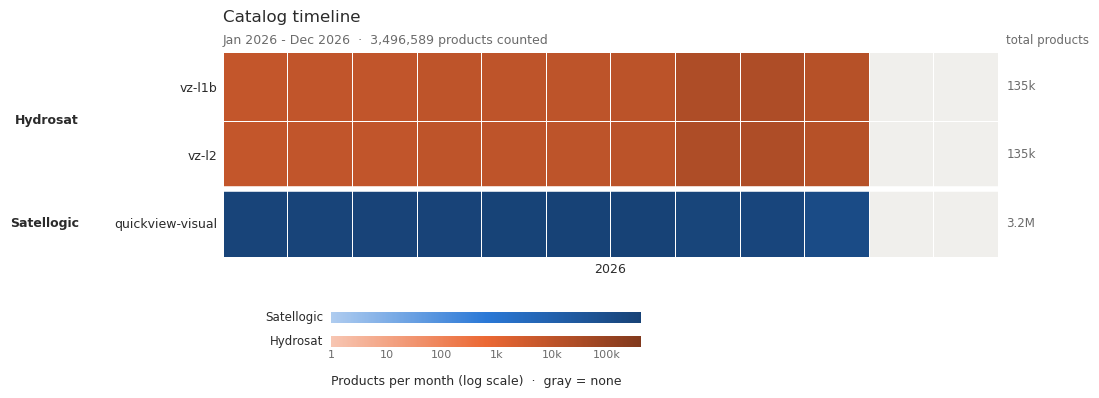

In [36]:
catalog_overview = multistac.overview(PROVIDERS, START, END)
catalog_months = multistac.overview_by_month(PROVIDERS, START, END)
multistac_plots.plot_month_heatmap(catalog_months, spans=catalog_overview, color_by='provider',
                                   start=START[:7], end=END[:7], title='Catalog timeline');
catalog_overview

## 2. Search the sites

In [37]:
%%time
res = multistac.search(sites, START, END, PROVIDERS, months=MONTHS,
                       cloud_cover_max=CLOUD_COVER_MAX, cache_dir=CACHE_DIR)
print(res)
res.log[res.log.status == 'failed']

searches: 100%|██████████| 684/684 [04:03<00:00,  2.81it/s] 


SearchResult(5728 rows, 4950 unique items, 6 failed tasks)
CPU times: user 1min 24s, sys: 1.52 s, total: 1min 26s
Wall time: 5min 20s


,provider,collection,site_name,interval,status,count,matched,server_filters,error,seconds
460,satellogic,quickview-visual,AZ Pima County,2026-01-01/2026-12-31,failed,0,NaN,eo:cloud_cover<=0 (cql2),satellogic: HTTP 502 for POST https://api.sate...,33.2
514,satellogic,quickview-visual,Gobabeb,2026-01-01/2026-12-31,failed,0,NaN,eo:cloud_cover<=0 (cql2),satellogic: HTTP 502 for POST https://api.sate...,34.7
515,satellogic,quickview-visual,Gobabeb TIR,2026-01-01/2026-12-31,failed,0,NaN,eo:cloud_cover<=0 (cql2),satellogic: HTTP 502 for POST https://api.sate...,71.5
527,satellogic,quickview-visual,La Crau,2026-01-01/2026-12-31,failed,0,NaN,eo:cloud_cover<=0 (cql2),satellogic: HTTP 502 for POST https://api.sate...,34.0
528,satellogic,quickview-visual,La Crau TIR,2026-01-01/2026-12-31,failed,0,NaN,eo:cloud_cover<=0 (cql2),satellogic: HTTP 502 for POST https://api.sate...,107.4
630,satellogic,quickview-visual,Railroad Valley,2026-01-01/2026-12-31,failed,0,NaN,eo:cloud_cover<=0 (cql2),satellogic: HTTP 502 for POST https://api.sate...,37.7


In [39]:
res.summary()

,provider,collection,processing_level,rows,products,acquisitions,sites
0,hydrosat,vz-l1b,L1B,699,310,310,182
1,hydrosat,vz-l2,L2,699,310,310,182
2,satellogic,quickview-visual,QUICKVIEW_VISUAL,4330,4330,1383,39


## 3. What do we have, and where?

**These counts are products, not acquisitions.** Each row of `res.gdf` is one catalog item, i.e. one *product*, and one acquisition (one satellite collect) is often delivered as several products:

- **Spectral products:** the panchromatic, multispectral and pansharpened products of one collect are separate items, e.g. Legion `P2AS` / `M2AS` / `S3DS`, Airbus `P` / `MS` / `PMS`, Maxar `P1BS` / `M1BS` in CMR. The `spectral_mode` column says which.
- **Processing levels:** the same collect at several levels (Legion `LV1B` / `LV2A` / `LV3D`, Satellogic `L1B` / `L1D_SR`).
- **File formats:** BlackSky delivers each collect as up to four items (GeoTIFF and NITF, ortho and non-ortho).

`acquisition_id` groups the products of one collect, so count `acquisition_id.nunique()` to answer "how many times was this site imaged?", and `id.nunique()` for "how many products are there?". The table below shows both.

**The plots take `count='products'` or `count='acquisitions'`** (`res.by_month(..., count=...)`, `plot_density_maps(..., count=...)`, `plot_distributions(..., count=...)`), and every title, axis and colorbar says which one is counted. Skyplots default to acquisitions (the products of one collect share its geometry).

Overlapping sites (e.g. WLEF and its skycams) also share products: count by `site_group` to count each product once per group (see the parameters section).


In [40]:
# Products vs acquisitions per constellation, and the product mix (spectral_mode x processing level)
g = res.gdf.drop_duplicates(['provider', 'id'])
counts = g.groupby(['affiliation', 'constellation']).agg(products=('id', 'size'), acquisitions=('acquisition_id', 'nunique'),
                                                        sites=('site_name', 'nunique'))
counts['products_per_acquisition'] = (counts.products / counts.acquisitions).round(2)
display(counts.sort_values('products', ascending=False))
g.groupby(['constellation', 'spectral_mode', 'processing_level'], dropna=False).size().unstack('processing_level', fill_value=0)


,,products,acquisitions,sites,products_per_acquisition
affiliation,constellation,,,,
Satellogic,Aleph-1,4330,1383,39,3.13
Hydrosat,VanZyl,620,310,108,2.00


,processing_level,L1B,L2,QUICKVIEW_VISUAL
constellation,spectral_mode,,,
Aleph-1,ms,0,0,4330
VanZyl,ms+tir,310,310,0


In [41]:
# Products (unique items) per site and constellation; see the table above for acquisitions
(res.gdf.groupby(['site_name', 'affiliation', 'constellation'])['id'].nunique()
    .unstack(['affiliation', 'constellation'], fill_value=0))

affiliation,Hydrosat,Satellogic
constellation,VanZyl,Aleph-1
site_name,,
AZ Coconino 1,12,0
AZ Coconino 2,10,0
AZ Maricopa Pinal,14,0
AZ Organ Pipe Cactus,6,0
AZ Pima County,4,0
...,...,...
Valencia,6,51
Venice,6,0


In [42]:
res.gdf.columns[0:20]

Index(['provider', 'affiliation', 'constellation', 'sensor', 'collection', 'id', 'datetime', 'site_name', 'site_group', 'cloud_cover', 'processing_level', 'product_type', 'spectral_mode',
       'acquisition_id', 'platform', 'instrument', 'gsd', 'off_nadir', 'incidence_angle', 'view_azimuth'],
      dtype='object')

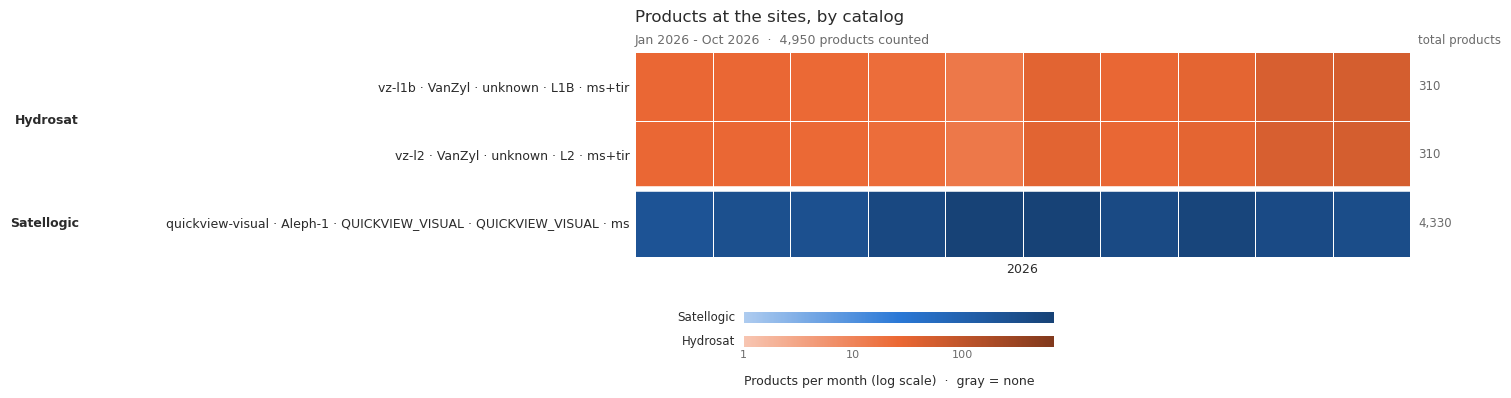

In [43]:
multistac_plots.plot_month_heatmap(res.by_month(['provider', 'collection','constellation','product_type','processing_level','spectral_mode'], count='products'), color_by='provider',
                                   title='Products at the sites, by catalog');

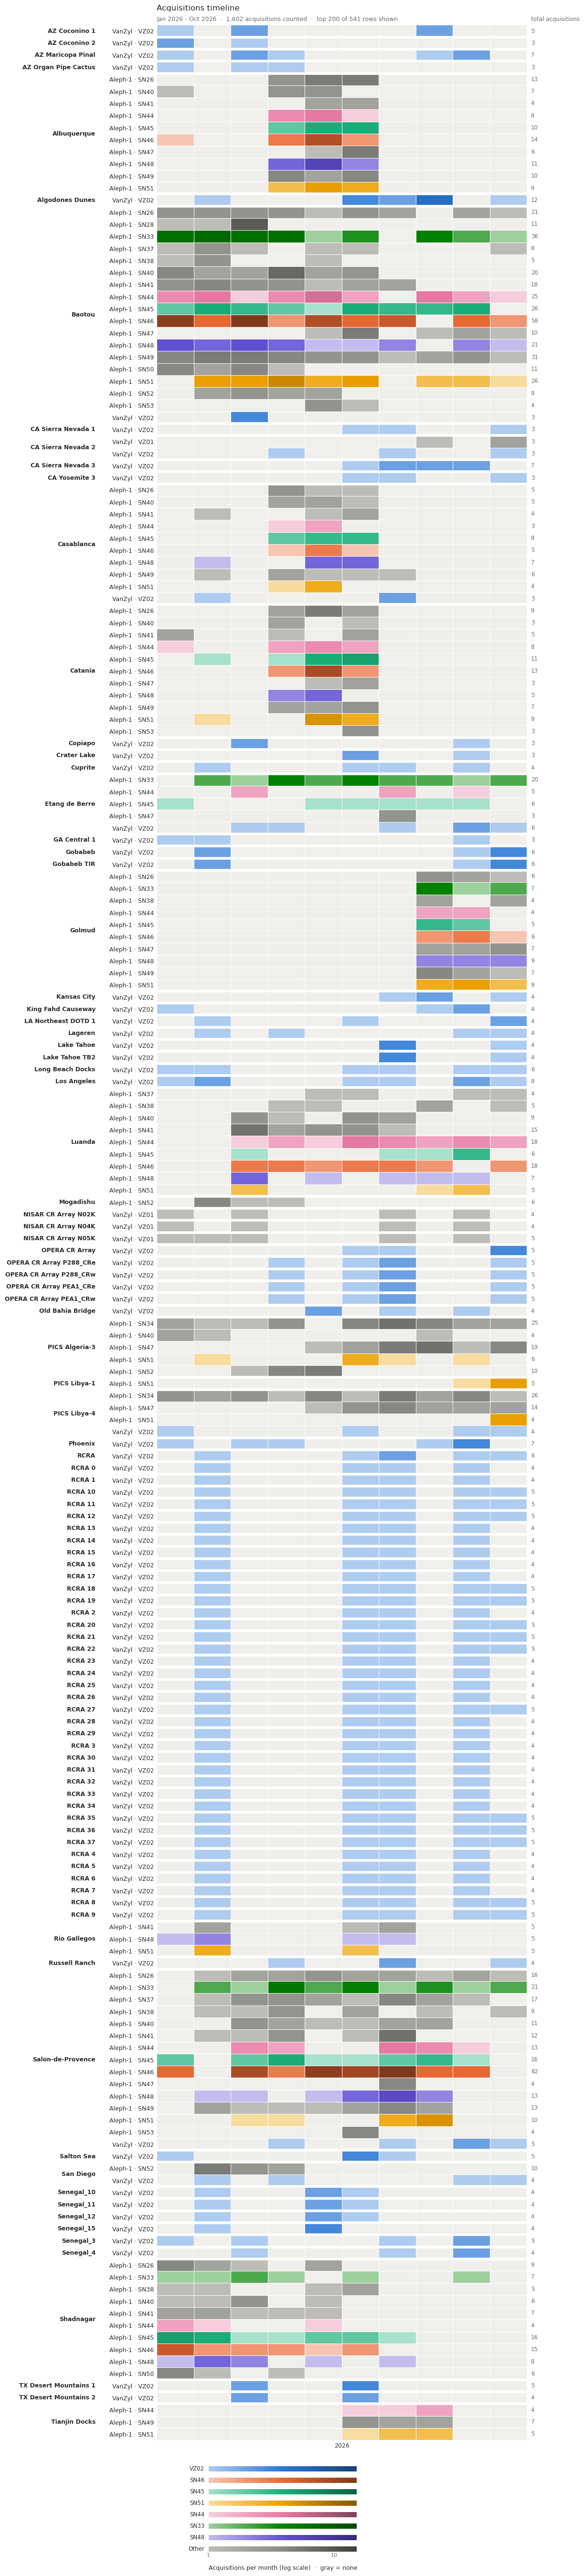

In [44]:
# Acquisitions: how often each site group was imaged (products of one collect counted once)
multistac_plots.plot_month_heatmap(res.by_month(['site_name','constellation','sensor'], count='acquisitions'), color_by='sensor', max_rows=200,
                                   title='Acquisitions timeline');

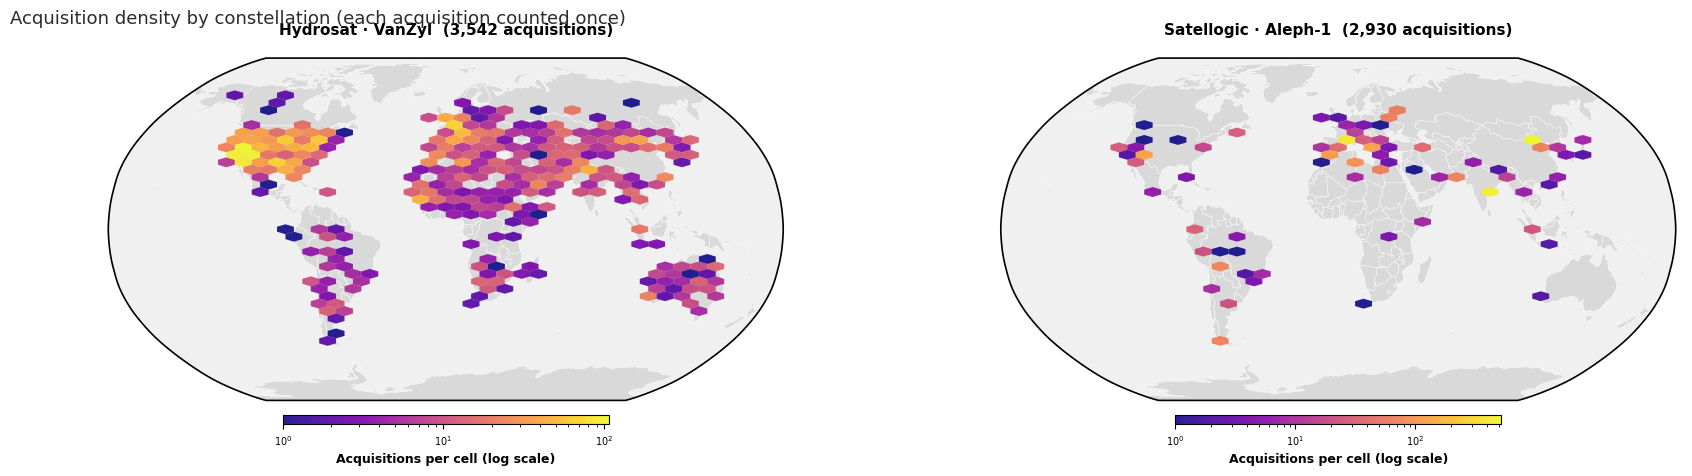

In [22]:
multistac_plots.plot_density_maps(res.gdf, facet_by=['affiliation','constellation'], max_facets=30, gridsize=40,
                                  count='acquisitions', title='Acquisition density by constellation (each acquisition counted once)');

In [23]:
# Which vendor-archive scenes CSDA already holds (vendor API rows only)
vendor_rows = res.gdf[res.gdf.in_csda.notna() & ~res.gdf.provider.isin(['csda', 'csda-cmr'])]
vendor_rows.groupby(['site_name', 'provider', 'in_csda']).size().unstack(fill_value=0) if len(vendor_rows) else 'no vendor-archive rows'

'no vendor-archive rows'

## 4. Inherent variation: cloud, resolution, view and sun geometry

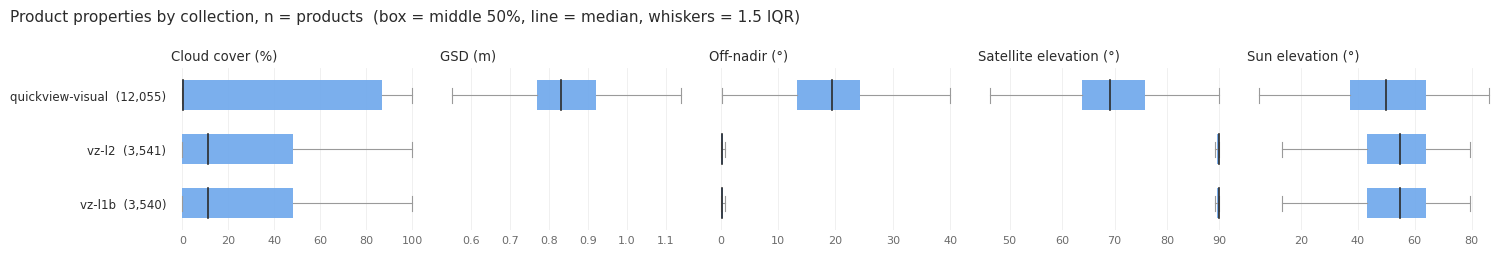

In [24]:
BY = 'csda:item_type' if 'csda:item_type' in res.gdf else 'collection'   # csda:item_type exists only for CSDA rows
multistac_plots.plot_distributions(res.gdf, count='products',   # GSD differs between a collect's pan and MS products

                                   by=BY
                                  #by = 'site_name'
                                  );

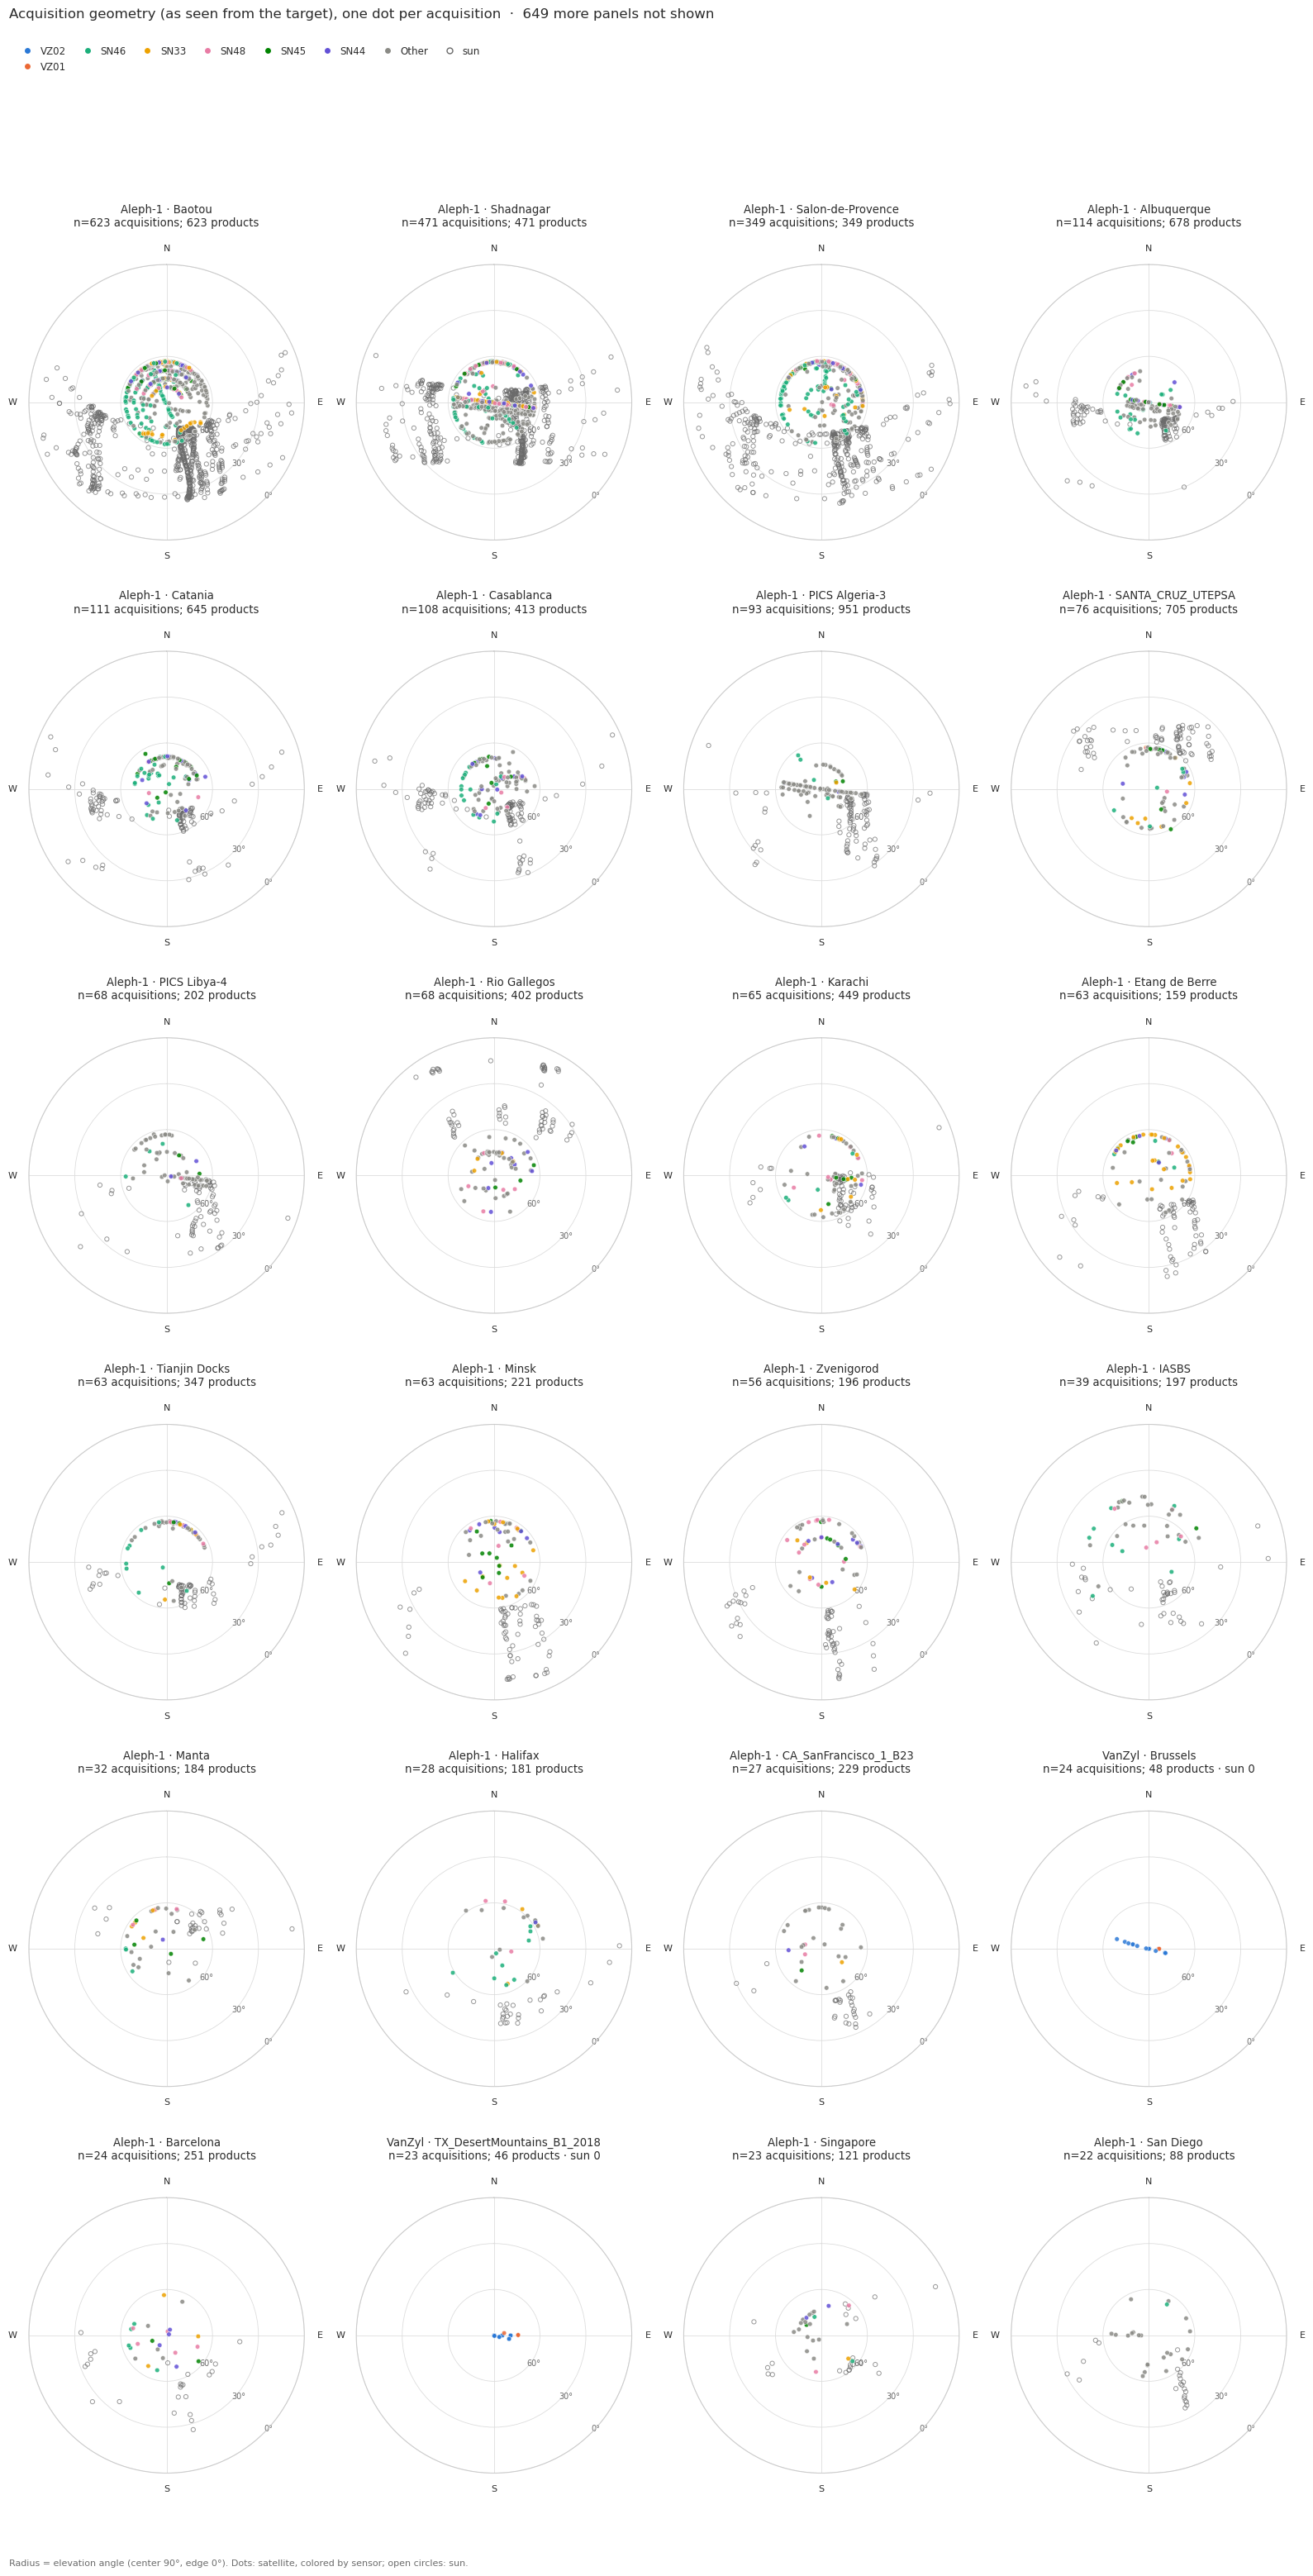

In [28]:
# Satellite and sun positions as seen from each site, one dot per acquisition (satellite colored by sensor).
# CMR rows have no azimuths and are left out; sat_elevation_source says when elevation is estimated.
multistac_plots.plot_skyplot(res.gdf, facet_by=['constellation','site_group'], color_by='sensor', panel_size=4);

In [27]:
# Geometry coverage: how many rows have each angle, by collection
geom_cols = ['sun_azimuth', 'sun_elevation', 'sat_azimuth', 'sat_elevation']
res.gdf.groupby(['provider', 'collection'])[geom_cols].count()

sun_azimuth  sun_elevation  sat_azimuth  sat_elevation
provider   collection                                                              
hydrosat   vz-l1b                      0           4241         4241           4241
           vz-l2                       0           4242         4242           4242
satellogic quickview-visual        13012          13012        13012          13012

In [31]:
# Footprints at one site (interactive). Not every site has results, so pick from those that do.
site_counts = res.gdf.site_name.value_counts()
#print(f'{len(site_counts)} of {len(sites)} sites have results:', ', '.join(f'{k} ({v})' for k, v in site_counts.items()))
missing = sorted(set(sites.site_name) - set(site_counts.index))
# if missing:
#     print('No results:', ', '.join(missing))

SITE = 'PICS Libya-4'                          # a site name, e.g. 'Railroad Valley'; None = the site with the most results
SITE = SITE or site_counts.index[0]
if SITE not in site_counts:
    print(f'No results for {SITE!r}; showing {site_counts.index[0]!r} instead (choose one of the sites listed above)')
    SITE = site_counts.index[0]
g = res.gdf[res.gdf.site_name == SITE]
cols = ['provider', 'constellation', 'sensor', 'spectral_mode', 'datetime', 'cloud_cover', 'gsd', 'off_nadir', 'geometry']
g[cols].assign(datetime=g.datetime.astype(str)).explore(column='constellation', tooltip=cols[:-1])

## 5. Select and download

Downloads go through the CSDA download API (CSDA STAC rows) or Earthdata HTTPS (CMR rows), using
`[EarthData]` username/password from your credentials INI. Vendor-archive rows (e.g. Satellogic API)
are not downloadable here; use their CSDA copies (`in_csda`).

In [29]:
# Choose what you want: any pandas filter on res.gdf
selection = multistac.apply_filters(
    res.gdf[res.gdf.provider.isin(['csda', 'csda-cmr'])],
    cloud_cover_max=20,
    where=lambda g: g.sat_elevation.ge(60) | g.sat_elevation.isna(),
)
print(f"{selection.id.nunique()} products from {selection.acquisition_id.nunique()} acquisitions selected ({len(selection)} product-site rows)")
# Products per site
selection.groupby(['site_name', 'constellation'])['id'].nunique().unstack(fill_value=0)

201 acquisitions selected


constellation,Legion
site_name,
Baotou,6
Belo Horizonte,14
Boston,6
Burjassot,4
Casablanca,4
Etang de Berre,2
Fort Huachuca,3
Kirtland_AFB,5
Marine Corps Mountain Warfare Center,6


In [30]:
# Assets available for the selection (keys differ by collection)
assets = multistac_download.list_assets(res)
assets[assets.collection.isin(selection.collection.unique())]

,provider,collection,asset,roles,items,download
0,csda,maxar-legion,IMD,metadata,125,csda_api
1,csda,maxar-legion,LICENSE,metadata,124,csda_api
2,csda,maxar-legion,README,metadata,125,csda_api
3,csda,maxar-legion,RPB,metadata,26,csda_api
4,csda,maxar-legion,TIL,metadata,125,csda_api
5,csda,maxar-legion,metadata,metadata,125,csda_api
6,csda,maxar-legion,thumbnail,thumbnail,125,csda_api
7,csda,maxar-legion,tile,data,20,csda_api
8,csda,maxar-legion,tile_r1c1,data,105,csda_api
9,csda,maxar-legion,tile_r1c2,data,99,csda_api


In [31]:
ASSETS = ['metadata', 'xml-metadata', 'xml', 'IMD']   # asset keys to fetch; or use ROLES
ROLES = None                                            # e.g. ['metadata'] or ['data', 'metadata']

plan = multistac_download.download(res, OUT_DIR, assets=ASSETS if ROLES is None else None, roles=ROLES,
                                   ids=selection['id'], dry_run=True)
print(plan.status.value_counts().to_dict())
plan[['provider', 'collection', 'id', 'asset', 'method', 'path']].tail(20)

{'planned': 238}


,provider,collection,id,asset,method,path
218,csda,maxar-legion,200012660116_01_P001_M2AS,IMD,csda_api,/explore/nobackup/people/pmontesa/multistac/si...
219,csda,maxar-legion,200012660116_01_P001_M2AS,metadata,csda_api,/explore/nobackup/people/pmontesa/multistac/si...
220,csda,maxar-legion,200012979378_01_P001_P3DS,IMD,csda_api,/explore/nobackup/people/pmontesa/multistac/si...
221,csda,maxar-legion,200012979378_01_P001_P3DS,metadata,csda_api,/explore/nobackup/people/pmontesa/multistac/si...
222,csda,maxar-legion,200012872445_01_P001_P2AS,IMD,csda_api,/explore/nobackup/people/pmontesa/multistac/si...
223,csda,maxar-legion,200012872445_01_P001_P2AS,metadata,csda_api,/explore/nobackup/people/pmontesa/multistac/si...
224,csda,maxar-legion,200012660116_01_P001_P2AS,IMD,csda_api,/explore/nobackup/people/pmontesa/multistac/si...
225,csda,maxar-legion,200012660116_01_P001_P2AS,metadata,csda_api,/explore/nobackup/people/pmontesa/multistac/si...
226,csda,maxar-legion,200012660092_01_P001_M2AS,IMD,csda_api,/explore/nobackup/people/pmontesa/multistac/si...
227,csda,maxar-legion,200012660092_01_P001_M2AS,metadata,csda_api,/explore/nobackup/people/pmontesa/multistac/si...


In [32]:
DO_DOWNLOAD = False   # set True to download the plan above
if DO_DOWNLOAD:
    manifest = multistac_download.download(res, OUT_DIR, assets=ASSETS if ROLES is None else None,
                                           roles=ROLES, ids=selection['id'])
    print(manifest.status.value_counts().to_dict())
    display(manifest[manifest.status == 'failed'][['provider', 'id', 'asset', 'error']].head())

## Save

In [ ]:
# Writes .gpkg, .csv, _items.geojson and _log.csv
# res.save(f'{OUT_DIR}/site_search_{START[:4]}_{END[:4]}')